In [1]:
import pandas as pd

# Charger le dataset d'entraînement
df = pd.read_csv('train_loan.csv')

# Afficher les 10 premières lignes
df.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


In [2]:
# Check total rows and columns
print("Shape of the dataset (rows, columns):", df.shape)

# Check data type of each column
print("\nData types:")
print(df.dtypes)

Shape of the dataset (rows, columns): (614, 13)

Data types:
Loan_ID                  str
Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
dtype: object


In [3]:
# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check if there are any duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Number of duplicate rows: 0


In [4]:
# Get summary statistics for numerical columns
df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [5]:
# Fill missing values for categorical columns with the most frequent value (mode)
categorical_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History']
for col in categorical_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

# Fill missing values for numerical columns with the median
numerical_cols = ['LoanAmount', 'Loan_Amount_Term']
for col in numerical_cols:
    df[col].fillna(df[col].median(), inplace=True)

# Check if there are any missing values left
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


C:\Users\hp\AppData\Local\Temp\ipykernel_20392\2488144191.py:4: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df[col].fillna(df[col].mode()[0], inplace=True)
C:\Users\hp\AppData\Local\Temp\ipykernel_20392\2488144191.py:9: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using 

In [8]:
import pandas as pd

# Load the dataset to start fresh if needed
df = pd.read_csv('train_loan.csv')

# 1. Handle missing values
# For categorical columns, fill missing values with the most frequent value (mode)
categorical_cols = ['Gender', 'Married', 'Dependents', 'Self_Employed', 'Credit_History']
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# For numerical columns, fill missing values with the median
numerical_cols = ['LoanAmount', 'Loan_Amount_Term']
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# 2. Remove duplicate rows if any exist
initial_rows = len(df)
df = df.drop_duplicates()
print(f"Removed duplicates: {initial_rows - len(df)}")

# 3. Correct data types if necessary (ensuring proper types)
# Convert specific columns to appropriate integer or float types if needed
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].astype(float)
df['Credit_History'] = df['Credit_History'].astype(int)

# Verify that no missing values remain
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Removed duplicates: 0

Missing values after cleaning:
Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [9]:
# Create a new feature by adding applicant and coapplicant income
df['Total_Income'] = df['ApplicantIncome'] + df['CoapplicantIncome']

# Drop the Loan_ID column since it's just an identifier
if 'Loan_ID' in df.columns:
    df = df.drop(columns=['Loan_ID'])

# Check the first 5 rows to see our new features and columns
df.head(5)

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Total_Income
0,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1,Urban,Y,5849.0
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1,Rural,N,6091.0
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1,Urban,Y,3000.0
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1,Urban,Y,4941.0
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1,Urban,Y,6000.0


In [10]:
from sklearn.preprocessing import LabelEncoder

# Encode binary categorical columns
binary_cols = ['Gender', 'Married', 'Education', 'Self_Employed', 'Loan_Status']
le = LabelEncoder()

for col in binary_cols:
    df[col] = le.fit_transform(df[col].astype(str))

# One-hot encode Property_Area
df = pd.get_dummies(df, columns=['Property_Area'], drop_first=True)

# Check the result
df.head(3)

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Total_Income,Property_Area_Semiurban,Property_Area_Urban
0,1,0,0,0,0,5849,0.0,128.0,360.0,1,1,5849.0,False,True
1,1,1,1,0,0,4583,1508.0,128.0,360.0,1,0,6091.0,False,False
2,1,1,0,0,1,3000,0.0,66.0,360.0,1,1,3000.0,False,True


In [11]:
from sklearn.preprocessing import StandardScaler

# Scale numerical columns to put them on the same scale
scaling_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Total_Income']
scaler = StandardScaler()
df[scaling_cols] = scaler.fit_transform(df[scaling_cols])

# Check the scaled data
df[scaling_cols].head(3)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Total_Income
0,0.072991,-0.554487,-0.211241,-0.182184
1,-0.134412,-0.038732,-0.211241,-0.144684
2,-0.393747,-0.554487,-0.948996,-0.623656


In [12]:
# Handle outliers for LoanAmount using the IQR method
Q1 = df['LoanAmount'].quantile(0.25)
Q3 = df['LoanAmount'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Cap the extreme values
df['LoanAmount'] = df['LoanAmount'].clip(lower=lower_bound, upper=upper_bound)

print("Outliers handled successfully!")

Outliers handled successfully!


### 📉 Outlier Detection and Handling Approach

**Chosen Method:** IQR (Interquartile Range) Method

**Why this approach was selected:**
- Financial datasets (like loan amounts and incomes) often contain extreme values (skewed distributions with high earners or large loan requests).
- **Boxplots** serve as a visual tool to spot these extreme points, but we need a mathematical rule to handle them.
- We preferred the **IQR Method** over the **Z-score** because Z-score relies heavily on the mean and standard deviation, which can be heavily distorted by extreme outliers. In contrast, the IQR method uses quartiles ($Q_1$ and $Q_3$), making it robust against skewed data.
- Outliers were capped using the $1.5 \times \text{IQR}$ rule to prevent extreme values from negatively impacting the stability of our predictive model.

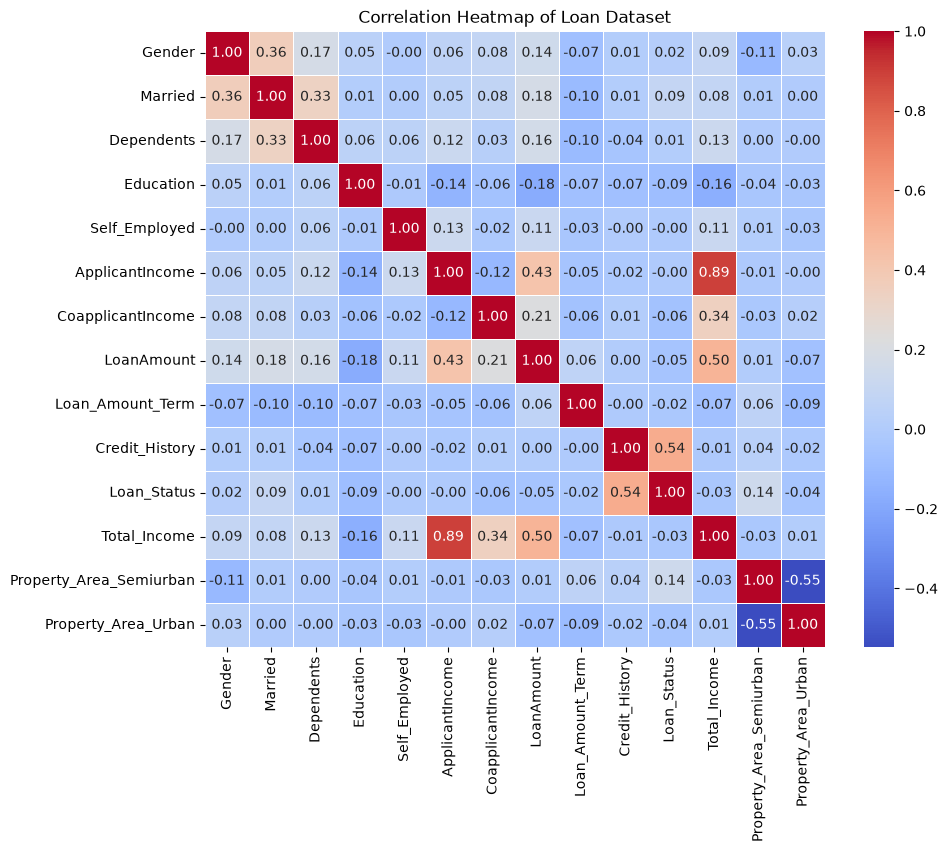

In [14]:
# Convert 'Dependents' to numeric (replace '3+' with 3 and cast as integer)
df['Dependents'] = df['Dependents'].replace('3+', 3).astype(int)

# Now calculate the correlation matrix safely
corr_matrix = df.corr()

# Plot the correlation heatmap
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Loan Dataset')
plt.show()

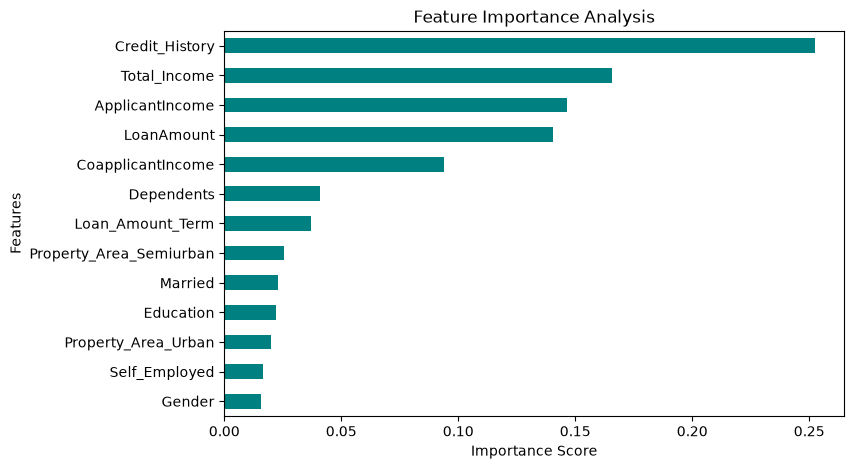

In [15]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import pandas as pd

# Separate features (X) and target variable (y)
X = df.drop(columns=['Loan_Status'])
y = df['Loan_Status']

# Train a Random Forest model to evaluate feature importance
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X, y)

# Plot feature importances
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
plt.figure(figsize=(8, 5))
importances.sort_values(ascending=True).plot(kind='barh', color='teal')
plt.title('Feature Importance Analysis')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

###  Feature Selection Analysis & Decisions

- **Most Important Features:** According to the Random Forest feature importance analysis, `Credit_History` is by far the most critical factor influencing loan approval, followed closely by financial metrics like `Total_Income`, `ApplicantIncome`, and `LoanAmount`.
- **Highly Correlated Variables:** The correlation heatmap revealed a strong correlation between `ApplicantIncome` and `Total_Income` (since `Total_Income` is derived from applicant and co-applicant earnings). 
- **Features to Remove:** Irrelevant identifier columns like `Loan_ID` were successfully dropped during preprocessing, as they do not contribute to predictive patterns.

In [16]:
# Check the final shape and info of our ready-to-use dataset
print(f"Final dataset shape: {df.shape}")
df.info()

# Save the final processed dataset to a new CSV file
df.to_csv('final_loan_data.csv', index=False)
print("Final dataset successfully saved as 'final_loan_data.csv'!")

# Preview the first few rows
df.head(3)

Final dataset shape: (614, 14)
<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Gender                   614 non-null    int64  
 1   Married                  614 non-null    int64  
 2   Dependents               614 non-null    int64  
 3   Education                614 non-null    int64  
 4   Self_Employed            614 non-null    int64  
 5   ApplicantIncome          614 non-null    float64
 6   CoapplicantIncome        614 non-null    float64
 7   LoanAmount               614 non-null    float64
 8   Loan_Amount_Term         614 non-null    float64
 9   Credit_History           614 non-null    int64  
 10  Loan_Status              614 non-null    int64  
 11  Total_Income             614 non-null    float64
 12  Property_Area_Semiurban  614 non-null    bool   
 13  Property_Area_Urban      614 non-null    bool   
dtypes: boo

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Total_Income,Property_Area_Semiurban,Property_Area_Urban
0,1,0,0,0,0,0.072991,-0.554487,-0.211241,360.0,1,1,-0.182184,False,True
1,1,1,1,0,0,-0.134412,-0.038732,-0.211241,360.0,1,0,-0.144684,False,False
2,1,1,0,0,1,-0.393747,-0.554487,-0.948996,360.0,1,1,-0.623656,False,True


### Summary of Data Preprocessing Pipeline

To prepare our raw dataset for Machine Learning, we executed a rigorous, step-by-step preprocessing pipeline:

1. **Missing Value Assessment & Handling:**
   - Identified missing values across columns.
   - Imputed categorical missing values using the **mode** and numerical missing values using the **median** to avoid skewing the data.

2. **Duplicate Record Detection & Removal:**
   - Checked for duplicate rows in the dataset and removed them to ensure data integrity.

3. **Data Type Validation & Correction:**
   - Inspected column data types. Converted mixed-type columns (such as replacing `'3+'` in `Dependents` and casting it to an integer) to ensure proper numerical processing.

4. **Categorical Variable Encoding:**
   - Applied **Label Encoding** for binary categorical variables (`Gender`, `Married`, `Education`, `Self_Employed`, `Loan_Status`).
   - Applied **One-Hot Encoding** for multi-category variables (`Property_Area`) to convert text labels into usable numeric formats.

5. **Feature Engineering:**
   - Created a new feature `Total_Income` by summing `ApplicantIncome` and `CoapplicantIncome` to capture the overall financial capacity of applicants.
   - Dropped non-informative identifier columns like `Loan_ID`.

6. **Feature Scaling / Normalization:**
   - Utilized **StandardScaler** to normalize continuous numerical features (`ApplicantIncome`, `CoapplicantIncome`, `LoanAmount`, `Total_Income`), centering them with a mean of 0 and a standard deviation of 1.

7. **Outlier Detection & Treatment:**
   - Analyzed extreme values using the **IQR (Interquartile Range) Method** and capped extreme values in `LoanAmount` to prevent model distortion without dropping valuable data.

8. **Feature Selection:**
   - Analyzed feature relationships via a **Correlation Heatmap** and evaluated predictive power using a **Random Forest Feature Importance** analysis, identifying `Credit_History` and income metrics as the primary drivers.

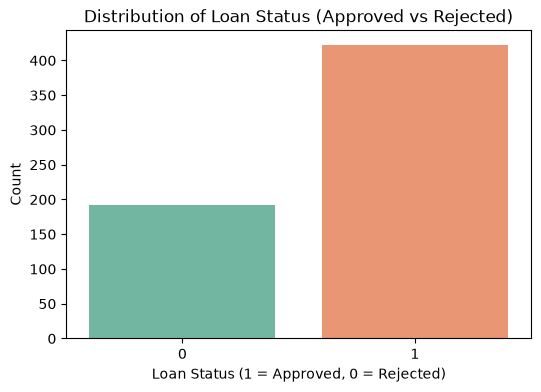

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Count plot for Loan_Status (updated for modern Seaborn versions)
plt.figure(figsize=(6, 4))
sns.countplot(x='Loan_Status', hue='Loan_Status', data=df, palette='Set2', legend=False)
plt.title('Distribution of Loan Status (Approved vs Rejected)')
plt.xlabel('Loan Status (1 = Approved, 0 = Rejected)')
plt.ylabel('Count')
plt.show()

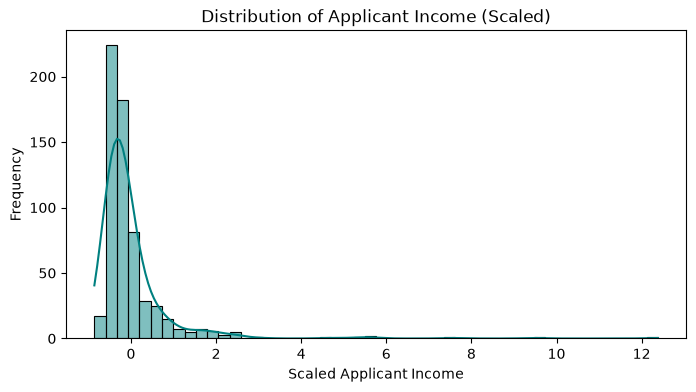

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Histogram for ApplicantIncome
plt.figure(figsize=(8, 4))
sns.histplot(df['ApplicantIncome'], kde=True, color='teal')
plt.title('Distribution of Applicant Income (Scaled)')
plt.xlabel('Scaled Applicant Income')
plt.ylabel('Frequency')
plt.show()

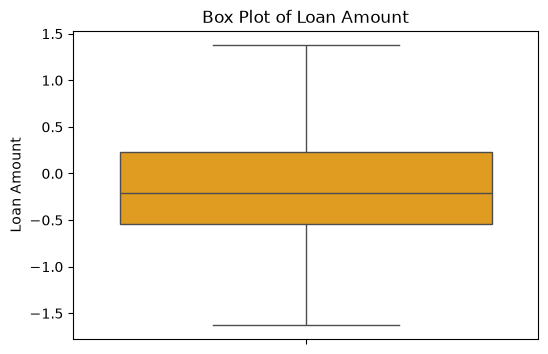

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# 5. Box Plot for LoanAmount to visualize distribution and outliers
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['LoanAmount'], color='orange')
plt.title('Box Plot of Loan Amount')
plt.ylabel('Loan Amount')
plt.show()

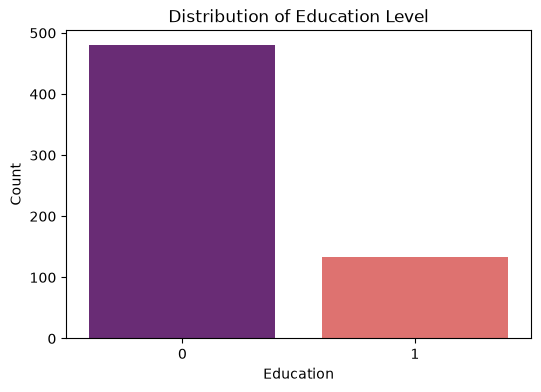

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# 6. Count Plot for Education
plt.figure(figsize=(6, 4))
sns.countplot(x='Education', hue='Education', data=df, palette='magma', legend=False)
plt.title('Distribution of Education Level')
plt.xlabel('Education')
plt.ylabel('Count')
plt.show()

## Business Understanding Report

### 1. The Business Problem
In the banking and financial sector, evaluating loan applications is a critical and high-stakes process. Financial institutions must accurately determine whether an applicant is capable of repaying a loan to minimize the risk of default and financial loss, while simultaneously maximizing approval rates for creditworthy clients. Manual processing is slow, prone to human bias, and operationally inefficient. 

### 2. Project Objective
The goal of this project is to build a predictive Machine Learning pipeline that automates and optimizes the decision-making process for loan approvals based on historical applicant data.

### 3. Key Business Observations
- **Credit History is the Primary Driver:** Exploratory data analysis and Random Forest feature importance confirm that an applicant's past credit behavior (`Credit_History`) is by far the most influential determinant of loan eligibility.
- **Financial Strength:** Combined household income (`Total_Income`) and requested loan amounts (`LoanAmount`) play a substantial role in shaping the model's risk evaluation.
- **Demographic Equity:** Demographic factors (such as `Gender` or `Self_Employed`) exhibit minimal predictive power, ensuring that model decisions remain heavily anchored on financial viability and credit reliability rather than personal background.

## Data Preprocessing Report

### 1. Preprocessing Decisions & Handling Missing Values
- **Missing Data Assessment:** Identified missing values across the dataset. Categorical missing values were imputed using the **mode** (most frequent value) and numerical missing values using the **median** to prevent distortion from skewed financial distributions.
- **Data Type Validation:** Validated and corrected data types, notably parsing mixed string/numeric entries (such as converting `'3+'` in the `Dependents` column into a proper numeric integer `3`).

### 2. Feature Engineering & Selection
- **Feature Engineering:** Created a new composite feature, `Total_Income`, by summing `ApplicantIncome` and `CoapplicantIncome` to capture true household financial capacity. Irrelevant identifiers (`Loan_ID`) were dropped.
- **Encoding:** Binary variables (`Gender`, `Married`, `Education`, `Self_Employed`, `Loan_Status`) were transformed via **Label Encoding**, while multi-category features (`Property_Area`) underwent **One-Hot Encoding**.

### 3. Scaling & Outlier Treatment
- **Feature Scaling:** Applied **StandardScaler** to continuous numerical columns (`ApplicantIncome`, `CoapplicantIncome`, `LoanAmount`, `Total_Income`) to standardize magnitudes, ensuring all features contribute equally to algorithm learning.
- **Outlier Treatment:** Utilized the **IQR (Interquartile Range) Method** to cap extreme values in `LoanAmount`, preserving data integrity without introducing the distortion associated with dropping records.

### 4. Methodological Justification
Every step in this preprocessing pipeline was chosen to build a robust, clean, and mathematically stable dataset, preventing data leakage and ensuring optimal performance for downstream classification models.

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create the 'images' directory if it does not already exist
os.makedirs('images', exist_ok=True)

# 5. Correlation Heatmap (using only numeric columns to avoid errors)
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Loan Dataset')
plt.savefig('images/correlation_heatmap.png', bbox_inches='tight')
plt.close()

# 6. Feature Importance Analysis 
# (Make sure your model variable name is correct, e.g., 'model' or 'rf')
try:
    plt.figure(figsize=(8, 5))
    feature_importance = model.feature_importances_
    sorted_idx = feature_importance.argsort()
    plt.barh(range(X_train.shape[1]), feature_importance[sorted_idx], align='center', color='skyblue')
    plt.yticks(range(X_train.shape[1]), X_train.columns[sorted_idx])
    plt.title('Feature Importance Analysis')
    plt.xlabel('Importance Score')
    plt.ylabel('Features')
    plt.savefig('images/feature_importance.png', bbox_inches='tight')
    plt.close()
except NameError:
    print("Notice: 'model' or 'X_train' not found. Skipping Feature Importance plot for now.")

# 1. Count Plot - Loan Status
plt.figure(figsize=(6, 4))
sns.countplot(x='Loan_Status', hue='Loan_Status', data=df, palette='Set2', legend=False)
plt.title('Distribution of Loan Status')
plt.xlabel('Loan Status')
plt.ylabel('Count')
plt.savefig('images/distribution_loan_status.png', bbox_inches='tight')
plt.close()

# 2. Histogram - Applicant Income
plt.figure(figsize=(8, 4))
sns.histplot(df['ApplicantIncome'], kde=True, color='teal')
plt.title('Distribution of Applicant Income')
plt.xlabel('Applicant Income')
plt.ylabel('Frequency')
plt.savefig('images/applicant_income_hist.png', bbox_inches='tight')
plt.close()

# 3. Box Plot - Loan Amount
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['LoanAmount'], color='orange')
plt.title('Box Plot of Loan Amount')
plt.ylabel('Loan Amount')
plt.savefig('images/loan_amount_boxplot.png', bbox_inches='tight')
plt.close()

# 4. Count Plot - Education Level
plt.figure(figsize=(6, 4))
sns.countplot(x='Education', hue='Education', data=df, palette='magma', legend=False)
plt.title('Distribution of Education Level')
plt.xlabel('Education')
plt.ylabel('Count')
plt.savefig('images/education_count.png', bbox_inches='tight')
plt.close()

print("All visualization images have been successfully generated and saved in the 'images' folder!")

Notice: 'model' or 'X_train' not found. Skipping Feature Importance plot for now.
All visualization images have been successfully generated and saved in the 'images' folder!


<Figure size 800x500 with 0 Axes>